In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

In [ ]:
X = np.load('..\Function_3_Data\Week_3_Data/F3_Week_3_inputs.npy')
Y = np.load('..\Function_3_Data\Week_3_Data/F3_Week_3_outputs.npy')
X.shape, Y

((17, 3),
 array([-0.1121222 , -0.08796286, -0.11141465, -0.03483531, -0.04800758,
        -0.11062091, -0.39892551, -0.11386851, -0.13146061, -0.09418956,
        -0.04694741, -0.10596504, -0.11804826, -0.03637783, -0.05675837,
        -0.05809956, -0.016422  ]))

In [48]:
Y_max=Y[0:-1].max()
Y_max_new=Y.max()
Y_max_new - Y_max

np.float64(0.018413312000803445)

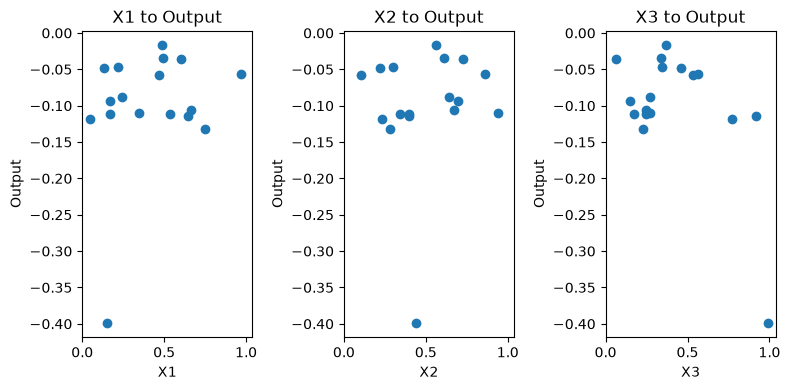

In [49]:
# Create 2 subplots
fig, axes = plt.subplots(1, 3, figsize=(8, 4), sharex=True)

# Scatterplots
axes[0].scatter(X[:,0], Y)
axes[0].set_title('X1 to Output')
axes[0].set_xlabel('X1')
axes[0].set_ylabel('Output')

axes[1].scatter(X[:,1], Y)
axes[1].set_title('X2 to Output')
axes[1].set_xlabel('X2')
axes[1].set_ylabel('Output')

axes[2].scatter(X[:,2], Y)
axes[2].set_title('X3 to Output')
axes[2].set_xlabel('X3')
axes[2].set_ylabel('Output')

plt.tight_layout()
plt.show()

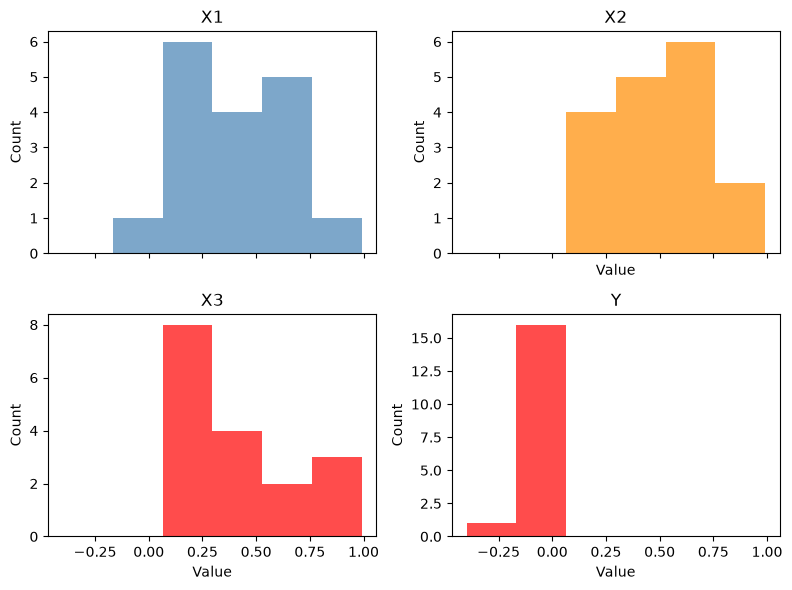

In [50]:
# Create 3 subplots
fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True)

# Use common bins for easy comparison
bins = np.linspace(
    min(X[:,0].min(), X[:,1].min(), X[:,2].min(), Y.min()),
    max(X[:,0].max(), X[:,1].max(), X[:,2].max(), Y.max()),
    7
)

# Histogram of first array
axes[0,0].hist(X[:,0], bins=bins, color='steelblue', alpha=0.7)
axes[0,0].set_title('X1')
axes[0,0].set_ylabel('Count')

# Histogram of second array
axes[0,1].hist(X[:,1], bins=bins, color='darkorange', alpha=0.7)
axes[0,1].set_title('X2')
axes[0,1].set_xlabel('Value')
axes[0,1].set_ylabel('Count')

# Histogram of third array
axes[1,0].hist(X[:,2], bins=bins, color='red', alpha=0.7)
axes[1,0].set_title('X3')
axes[1,0].set_xlabel('Value')
axes[1,0].set_ylabel('Count')

# Histogram of target
axes[1,1].hist(Y, bins=bins, color='red', alpha=0.7)
axes[1,1].set_title('Y')
axes[1,1].set_xlabel('Value')
axes[1,1].set_ylabel('Count')

plt.tight_layout()
plt.show()

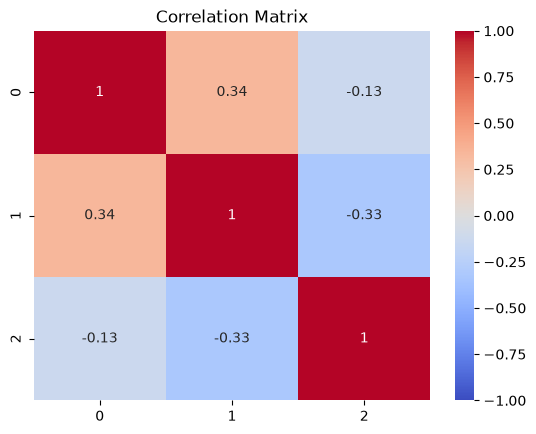

In [51]:
df=pd.DataFrame(data=X)
corr = df.corr()

sns.heatmap(corr,
            annot=True,
            cmap='coolwarm',
            vmin=-1,
            vmax=1)

plt.title("Correlation Matrix")
plt.show()

In [52]:
length_scale_vector = np.ones(X.shape[1])
#kernel = Matern(length_scale=[0.5, 0.5, 0.5], nu=2.5)
kernel = ConstantKernel(1.0) * RBF(length_scale=length_scale_vector)
gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6, n_restarts_optimizer=10)
gp.fit(X, Y)

,"kernel kernel: kernel instance, default=NoneThe kernel specifying the covariance function of the GP.If `None` is passed,the kernel `ConstantKernel() * RBF()` is used as default.Note thatthe kernel hyperparameters are optimized during fittingunless the bounds are marked as `""fixed""`or the argument `optimizer` is set to `None`.","1**2 * RBF(le...ale=[1, 1, 1])"
,"alpha alpha: float or ndarray of shape (n_samples,), default=1e-10Value added to the diagonal of the kernel matrix during fitting.This can prevent a potential numerical issue during fitting, byensuring that the calculated values form a positive definite matrix.It can also be interpreted as the variance of additional Gaussianmeasurement noise on the training observations. Note that this isdifferent from using a `WhiteKernel`. If an array is passed, it musthave the same number of entries as the data used for fitting and isused as datapoint-dependent noise level. Allowing to specify thenoise level directly as a parameter is mainly for convenience andfor consistency with :class:`~sklearn.linear_model.Ridge`.For an example illustrating how the alpha parameter controlsthe noise variance in Gaussian Process Regression, see:ref:`sphx_glr_auto_examples_gaussian_process_plot_gpr_noisy_targets.py`.",1e-06
,"n_restarts_optimizer n_restarts_optimizer: int, default=0The number of restarts of the optimizer for finding the kernel'sparameters which maximize the log-marginal likelihood. The first runof the optimizer is performed from the kernel's initial parameters,the remaining ones (if any) from thetas sampled log-uniform randomlyfrom the space of allowed theta-values. If greater than 0, all boundsmust be finite. Note that `n_restarts_optimizer == 0` implies that onerun is performed.",10
,kernel__k1,1**2
,kernel__k2,"RBF(length_scale=[1, 1, 1])"
,kernel__k1__constant_value,1.0
,kernel__k1__constant_value_bounds,"(1e-05, ...)"
,kernel__k2__length_scale,"array([1., 1., 1.])"
,kernel__k2__length_scale_bounds,"(1e-05, ...)"
,"optimizer optimizer: ""fmin_l_bfgs_b"", callable or None, default=""fmin_l_bfgs_b""Can either be one of the internally supported optimizers for optimizingthe kernel's parameters, specified by a string, or an externallydefined optimizer passed as a callable. If a callable is passed, itmust have the signature:: def optimizer(obj_func, initial_theta, bounds): # * 'obj_func': the objective function to be minimized, which # takes the hyperparameters theta as a parameter and an # optional flag eval_gradient, which determines if the # gradient is returned additionally to the function value # * 'initial_theta': the initial value for theta, which can be # used by local optimizers # * 'bounds': the bounds on the values of theta .... # Returned are the best found hyperparameters theta and # the corresponding value of the target function. return theta_opt, func_minPer default, the L-BFGS-B algorithm from `scipy.optimize.minimize`is used. If None is passed, the kernel's parameters are kept fixed.Available internal optimizers are: `{'fmin_l_bfgs_b'}`.",'fmin_l_bfgs_b'
,"normalize_y normalize_y: bool, default=FalseWhether or not to normalize the target values `y` by removing the meanand scaling to unit-variance. This is recommended for cases wherezero-mean, unit-variance priors are used. Note that, in thisimplementation, the normalisation is reversed before the GP predictionsare reported... versionchanged:: 0.23",False


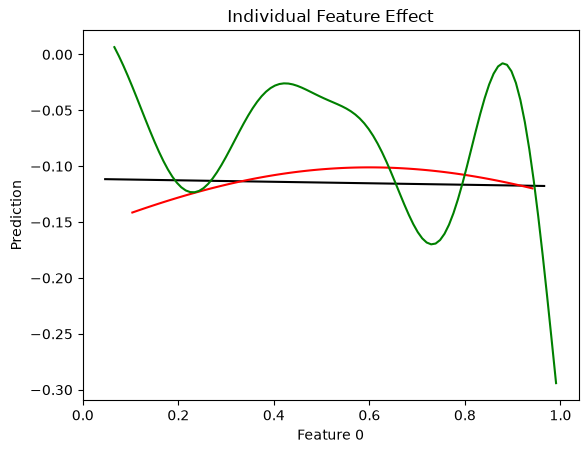

In [53]:
sample = X[0].copy()



feature0 = 0
feature1 = 1
feature2 = 2
values0 = np.linspace(X[:, feature0].min(), X[:, feature0].max(), 100)
values1 = np.linspace(X[:, feature1].min(), X[:, feature1].max(), 100)
values2 = np.linspace(X[:, feature2].min(), X[:, feature2].max(), 100)

predictions0 = []
predictions1 = []
predictions2 = []

for v in values0:
    temp = sample.copy()
    temp[feature0] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions0.append(pred)
for v in values1:
    temp = sample.copy()
    temp[feature1] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions1.append(pred)
for v in values0:
    temp = sample.copy()
    temp[feature2] = v
    pred = gp.predict(temp.reshape(1, -1))[0]
    predictions2.append(pred)
    
plt.plot(values0, predictions0, color = 'black')
plt.plot(values1, predictions1, color = 'red')
plt.plot(values2, predictions2, color = 'green')
plt.xlabel("Feature 0")
plt.ylabel("Prediction")
plt.title("Individual Feature Effect")
plt.show()

In [55]:
def upper_confidence_bound(mu, sigma, kappa=2.0):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma
    
def lower_confidence_bound(mu, sigma, kappa=2.0):
    """
    Lower Confidence Bound (UCB) acquisition function.
    LCB = mean - kappa * std
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu - kappa * sigma

def expected_improvement(mu, sigma, y_best, xi=0.1):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei


In [58]:
def acq_objective(X):
    X = X.reshape(1, -1)
    mu, sigma = gp.predict(X, return_std=True)
               
    if acquisition == 'ei':
        acq_val = expected_improvement(mu, sigma, Y.max())
    elif acquisition == 'lcb':
        acq_val = lower_confidence_bound(mu, sigma, kappa=5)
    else:
        acq_val = upper_confidence_bound(mu, sigma, kappa=2.5)
           
    return -acq_val  # Negative because we use the 'minimize' function later

In [59]:
acquisition='lcb'
n_dims=X.shape[1]
bounds = [(0, 1) for _ in range(n_dims)]
best_acq = np.inf
X_next = None

bounds = [(0, 1) for _ in range(n_dims)]
for _ in range(50):  # Multiple random starts
    x0 = np.random.uniform(0, 1, n_dims)
    result = minimize(acq_objective, x0, bounds=bounds, method='L-BFGS-B')
    if result.fun < best_acq:
        best_acq = result.fun
        X_next = result.x

print(f'New query: {X_next[0]:.6f}-{X_next[1]:.6f}-{X_next[2]:.6f}') 
# New query1: 0.487520-0.564190-0.371494 - lcb
# New query2: 0.507753-0.542831-0.397394 - lcb
# New query3: 0.425811-0.567618-0.387847 - lcb - kappa = 2.5 - 05.08.26
#

New query: 0.466964-0.559710-0.380367


In [ ]:
X_new = np.vstack((X, X_next))
#X_new = X_new.reshape(1, -1)
mu, sigma = gp.predict(X_new, return_std=True)
mu